<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp17_Mobile_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 17: Mobile Price Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement Mobile Price Prediction using an appropriate machine learning algorithm.

## Background
Given a phone's specifications (RAM, battery, screen resolution, memory, camera ...), predict its **price range** (0 = low, 1 = medium, 2 = high, 3 = very high). Since the target is an ordered *category*, this is a **multi-class classification** problem. We compare Logistic Regression, SVM, K-NN, Decision Tree and Random Forest.


## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We generate **2,000 mobile phones** with 20 specifications (mirroring the popular Kaggle *Mobile Price Classification* data). The price range is derived from a hidden value score dominated by RAM, then battery, resolution and storage (plus noise), split into four equal-sized bands. Saved as `mobile_price.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 2000
zs = lambda v: (v - v.mean()) / v.std()

ram = rng.randint(256, 4000, n)
battery = rng.randint(500, 2000, n)
px_height = rng.randint(0, 1960, n)
px_width = rng.randint(500, 1998, n)
int_memory = rng.randint(2, 64, n)
pc = rng.randint(0, 20, n)
n_cores = rng.randint(1, 9, n)

value = (0.55 * zs(ram) + 0.25 * zs(battery) + 0.20 * zs(px_height * px_width) + 0.10 * zs(int_memory)
         + 0.08 * zs(pc) + 0.05 * zs(n_cores) + rng.normal(0, 0.10, n))
price_range = np.digitize(value, np.quantile(value, [0.25, 0.5, 0.75]))        # 0,1,2,3

pd.DataFrame({
    "battery_power": battery, "blue": rng.randint(0, 2, n), "clock_speed": rng.uniform(0.5, 3.0, n).round(1),
    "dual_sim": rng.randint(0, 2, n), "fc": rng.randint(0, 20, n), "four_g": rng.randint(0, 2, n),
    "int_memory": int_memory, "m_dep": rng.uniform(0.1, 1.0, n).round(1), "mobile_wt": rng.randint(80, 200, n),
    "n_cores": n_cores, "pc": pc, "px_height": px_height, "px_width": px_width, "ram": ram,
    "sc_h": rng.randint(5, 20, n), "sc_w": rng.randint(0, 19, n), "talk_time": rng.randint(2, 21, n),
    "three_g": rng.randint(0, 2, n), "touch_screen": rng.randint(0, 2, n), "wifi": rng.randint(0, 2, n),
    "price_range": price_range}).to_csv("mobile_price.csv", index=False)
print("Saved mobile_price.csv")

Saved mobile_price.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("mobile_price.csv")
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,1271,1,2.6,0,6,0,34,0.8,99,8,...,1845,1424,3430,8,16,11,0,0,1,3
1,1833,1,1.9,1,0,0,18,0.3,151,2,...,1708,993,3763,12,10,10,1,0,1,3
2,1384,1,1.0,1,8,0,25,0.9,80,6,...,1582,1621,1116,13,9,9,0,0,1,1
3,1766,1,2.1,1,10,0,38,0.9,135,5,...,1163,1594,1550,16,16,20,1,0,1,2
4,1889,0,1.4,0,18,0,58,0.3,149,3,...,245,863,1386,8,0,4,0,0,1,1


## Step 3: Data Preprocessing
Check quality and remove impossible values (a screen width of 0 cm, a pixel height of 0), then split and scale. Pixel height/width of 0 are impossible, so we replace them with the median.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
print("Impossible zeros -> px_height:", (df.px_height == 0).sum(), "| sc_w:", (df.sc_w == 0).sum())
for col in ["px_height", "sc_w"]:
    df[col] = df[col].replace(0, df.loc[df[col] > 0, col].median())

# Feature engineering: total pixels and screen area
df["pixels"] = df["px_height"] * df["px_width"]
df["screen_area"] = df["sc_h"] * df["sc_w"]

X = df.drop(columns="price_range")
y = df["price_range"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", X_train.shape, "Test:", X_test.shape)

Missing values: 0 | Duplicates: 0
Impossible zeros -> px_height: 1 | sc_w: 110
Train: (1600, 22) Test: (400, 22)


## Step 4: Exploratory Data Analysis (EDA)

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


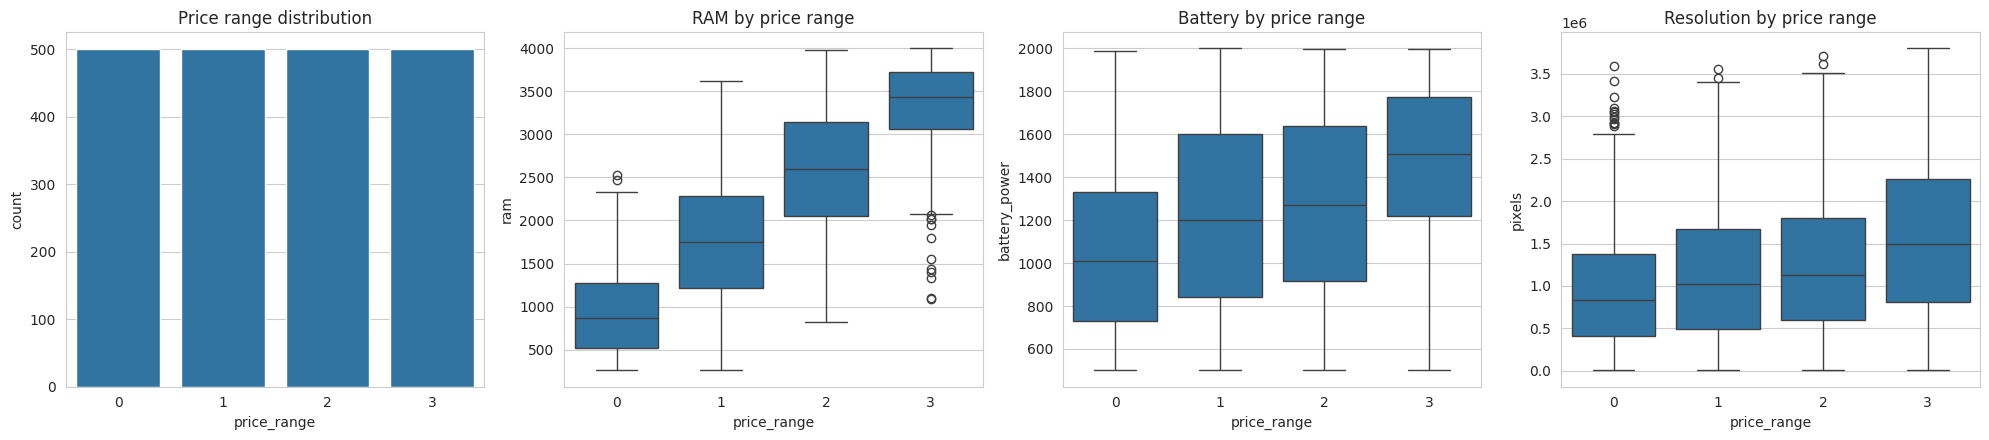

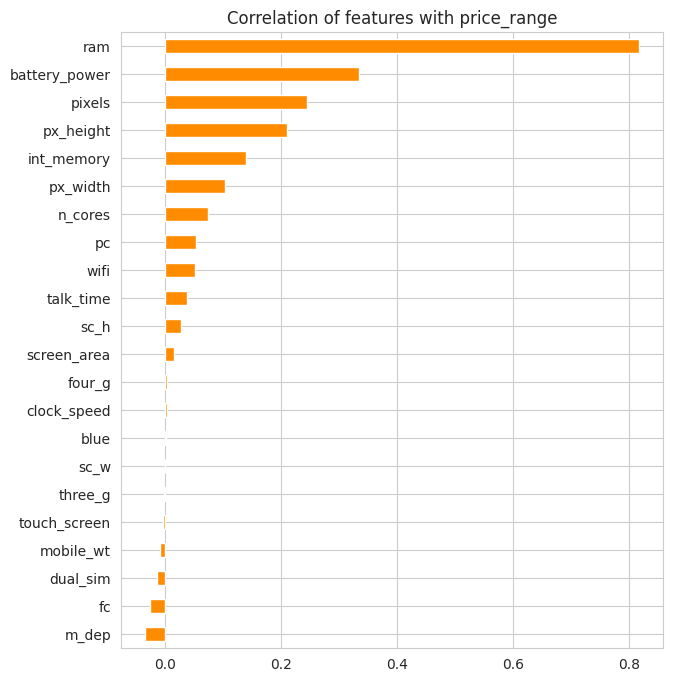

In [5]:
print(df["price_range"].value_counts().sort_index())
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.countplot(data=df, x="price_range", ax=axes[0]); axes[0].set_title("Price range distribution")
sns.boxplot(data=df, x="price_range", y="ram", ax=axes[1]); axes[1].set_title("RAM by price range")
sns.boxplot(data=df, x="price_range", y="battery_power", ax=axes[2]); axes[2].set_title("Battery by price range")
sns.boxplot(data=df, x="price_range", y="pixels", ax=axes[3]); axes[3].set_title("Resolution by price range")
plt.tight_layout(); plt.show()

corr = df.corr()["price_range"].drop("price_range").sort_values()
corr.plot(kind="barh", figsize=(7, 8), color="darkorange", title="Correlation of features with price_range"); plt.show()

## Step 5: Model Training
Train five classifiers and compare them with 5-fold cross-validation.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "SVM (linear)": SVC(kernel="linear", probability=True, random_state=42),
    "K-NN": KNeighborsClassifier(n_neighbors=9),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
cv = {name: cross_val_score(m, X_train_s, y_train, cv=5, scoring="accuracy") for name, m in models.items()}
for name, s in cv.items():
    print(f"{name:<22} CV accuracy = {s.mean():.4f} (+/- {s.std():.4f})")
best_name = max(cv, key=lambda k: cv[k].mean())
best = models[best_name].fit(X_train_s, y_train)
print("\nSelected model:", best_name)

Logistic Regression    CV accuracy = 0.8700 (+/- 0.0197)
SVM (linear)           CV accuracy = 0.8738 (+/- 0.0238)
K-NN                   CV accuracy = 0.5019 (+/- 0.0256)
Decision Tree          CV accuracy = 0.7013 (+/- 0.0279)
Random Forest          CV accuracy = 0.7656 (+/- 0.0332)

Selected model: SVM (linear)


## Step 6: Model Evaluation
Test-set accuracy, per-class report, confusion matrix, and feature importance (using a Random Forest).

Test accuracy: 0.8475
              precision    recall  f1-score   support

         low       0.89      0.90      0.90       100
      medium       0.78      0.77      0.77       100
        high       0.79      0.81      0.80       100
   very high       0.93      0.91      0.92       100

    accuracy                           0.85       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.85      0.85      0.85       400



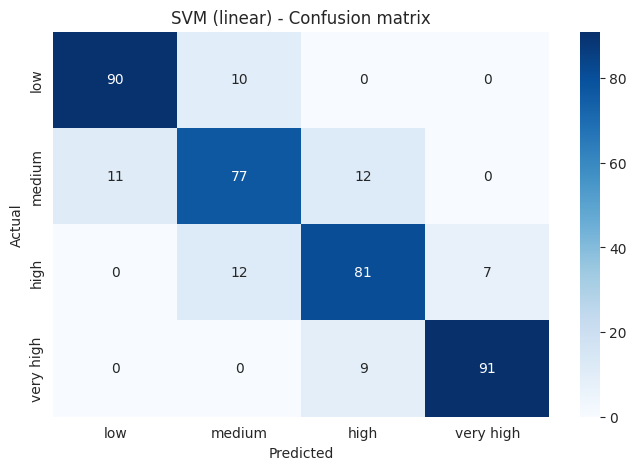

Predictions off by 0 / 1 / 2+ bands: [np.int64(339), np.int64(61), np.int64(0)]


In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = best.predict(X_test_s)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["low", "medium", "high", "very high"]))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["low", "medium", "high", "very high"], yticklabels=["low", "medium", "high", "very high"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"{best_name} - Confusion matrix"); plt.show()

# Mistakes are almost always one band away (ordinal target)
off_by = np.abs(y_pred - y_test.values)
print("Predictions off by 0 / 1 / 2+ bands:", [(off_by == k).sum() if k < 2 else (off_by >= 2).sum() for k in range(3)])

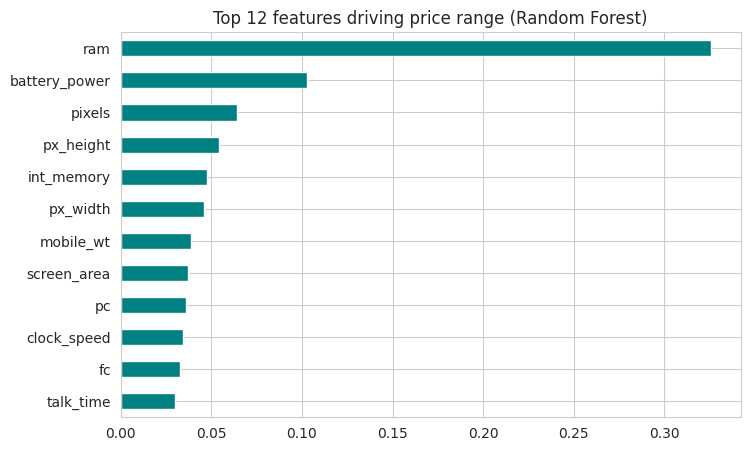

In [8]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(12).plot(kind="barh", color="teal", figsize=(8, 5))
plt.title("Top 12 features driving price range (Random Forest)"); plt.show()

## Step 7: Prediction on New Data

In [9]:
new_phone = pd.DataFrame([{
    "battery_power": 1800, "blue": 1, "clock_speed": 2.2, "dual_sim": 1, "fc": 12, "four_g": 1, "int_memory": 48,
    "m_dep": 0.5, "mobile_wt": 140, "n_cores": 8, "pc": 16, "px_height": 1500, "px_width": 1700, "ram": 3500,
    "sc_h": 15, "sc_w": 8, "talk_time": 15, "three_g": 1, "touch_screen": 1, "wifi": 1}])
new_phone["pixels"] = new_phone["px_height"] * new_phone["px_width"]
new_phone["screen_area"] = new_phone["sc_h"] * new_phone["sc_w"]
new_phone = new_phone[X.columns]

labels = ["low", "medium", "high", "very high"]
proba = best.predict_proba(scaler.transform(new_phone))[0]
print("Predicted price range:", labels[int(np.argmax(proba))])
print("Probabilities:", dict(zip(labels, proba.round(3))))

Predicted price range: very high
Probabilities: {'low': np.float64(0.0), 'medium': np.float64(0.0), 'high': np.float64(0.0), 'very high': np.float64(1.0)}


## Conclusion
RAM is the strongest predictor of price range, followed by battery power and screen resolution (see the importance plot) - the pattern built into the data. Because the underlying value score is linear, Logistic Regression and the linear SVM perform best (about 85-87% accuracy); Random Forest and the Decision Tree are weaker, and K-NN is weakest because many irrelevant features dilute the distance measure. Almost all errors are between *adjacent* price bands, which is acceptable for an ordered target. Real-world data would add brand and market effects.